# 🤖 Supervised Learning for Oil Well Fault Detection

## What is Supervised Classification?

Supervised learning uses labeled training data to predict categories for new data.

**Key Components:**
- **Training Data**: Examples with known answers (features + labels)
- **Features**: Sensor measurements (input)
- **Labels**: Fault types 0-9 (output)
- **Model**: Algorithm that learns patterns
- **Evaluation**: How well the model performs

## Our Problem: 3W Oil Well Classification

**Goal**: Predict oil well fault types from sensor data

**Input**: Time series from sensors (P-PDG, P-TPT, T-TPT)
**Output**: Fault classes (0=normal, 1-9=different faults)
**Challenge**: Multiple classes, imbalanced data, high dimensions

> 📖 **Companion book** — this notebook exercises **Chapter 4** (*Aprendizado de máquina e avaliação*: the supervised formulation, the confusion matrix, balanced accuracy and validation) and **Chapter 8** (the binary-classifier ensemble) of Lopes et al. (2026), *Aprendizado de Mundo Aberto em Poços de Petróleo* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)). **Appendix E** (§*Caderno 4*) describes the six models trained here.
>
> 🧰 **3W Toolkit** — the metrics come from `ThreeWToolkit.metrics` and the confusion matrix from `AssessmentVisualization`. Every classifier is created through the toolkit `SklearnModelsConfig(...).build()`, and the first example below walks through one model end to end with the toolkit only. The *by-fold* analyses that follow keep our own loop (balanced training, per-fold tables, overfitting and consistency dashboards), which the toolkit does not have. For the toolkit's own `SklearnTrainer`, `MLP`, `ModelAssessment` and `Pipeline` see the [model training](../introduction_to_3w_toolkit_v2.0.0/7_model_training_and_evaluation.ipynb) and [pipeline integration](../introduction_to_3w_toolkit_v2.0.0/8_pipeline_integration.ipynb) tutorials.

In [1]:
# ============================================================
# LOAD 3W DATASET
# ============================================================

import sys
import numpy as np

# Add src directory to path
sys.path.append("src")
from src import config
from src.supervised_classification import (
    load_3w_data,
)

# Load dataset using utility function
(train_dfs, train_classes, train_fold_info, test_dfs, test_classes, test_fold_info) = (
    load_3w_data(config, verbose=True)
)

Loading 3W Dataset for Classification
Found 3 folds


✅ Data loaded successfully!
   Training windows: 69128
   Test windows: 15964
   Window shape: (300, 4)


## Data Loading for Supervised Learning

**Key requirements:**
- **Labeled data** - Examples with known fault classifications
- **Train/test split** - Separate data for training and unbiased evaluation
- **Cross-validation** - Multiple data splits for robust performance estimates

**3W Dataset structure:**
- **Training data** - Used to teach algorithms to recognize patterns
- **Test data** - Unseen data to evaluate real-world performance
- **Windowed format** - Time series converted to fixed-size sequences
- **Class labels** - Fault types (0=normal, 1-8=different fault conditions)

# 📊 Classification Configuration

## Class Selection

Choose which fault types to analyze:

```python
selected_classes = [3, 4, 8]  # Focus on specific faults
selected_classes = [1, 2, 3, 4, 5]  # Early fault types  
selected_classes = None  # All fault types (exclude normal operation)
```

In [2]:
# ============================================================
# CONFIGURE CLASSIFICATION
# ============================================================
import pandas as pd

selected_classes = [3, 4, 8]  # Choose fault types to analyze

print("Classification Configuration:")
print("=" * 35)

if not (train_dfs and test_dfs):
    print("❌ No data available. Run the data loading cell first.")
else:
    print(f"✅ Data ready: {len(train_dfs)} train, {len(test_dfs)} test windows")
    missing = [c for c in selected_classes if str(c) not in set(test_classes)]
    print(f"Selected classes: {selected_classes}" + (f" ⚠️ not in the data: {missing}" if missing else ""))
    print(f"✅ Fold information: {len(set(test_fold_info))} folds detected")

    # Test windows of each class in each fold
    distribution = pd.crosstab(
        pd.Series(test_classes, name="Class"),
        pd.Series(test_fold_info, name="Fold"),
        margins=True,
        margins_name="Total",
    )
    print("\n📊 CLASS DISTRIBUTION BY TEST FOLD (windows)")
    print(distribution.to_string())

    chosen = distribution.loc[[str(c) for c in selected_classes]].sum()
    print(f"\n🎯 Selected classes {selected_classes} in each fold (share of the test windows):")
    print((100 * chosen / distribution.loc["Total"]).round(1).astype(str).add(" %").to_string())

Classification Configuration:
✅ Data ready: 69128 train, 15964 test windows
Selected classes: [3, 4, 8]
✅ Fold information: 3 folds detected

📊 CLASS DISTRIBUTION BY TEST FOLD (windows)
Fold   fold_1  fold_2  fold_3  Total
Class                               
0         374     374     362   1110
1         126      70      94    290
2          46      58     113    217
3         242     238     220    700
4         136     133     136    405
5          63     283     171    517
6          16      45       5     66
7        3150    3316    1607   8073
8         382     820    1608   2810
9         638     277     861   1776
Total    5173    5614    5177  15964

🎯 Selected classes [3, 4, 8] in each fold (share of the test windows):
Fold
fold_1    14.7 %
fold_2    21.2 %
fold_3    37.9 %
Total     24.5 %


## Multi-Algorithm Training Strategy

**Algorithm categories:**
- **Tree-based** - can be (depends on the algoritm and application): Interpretable, handle non-linear patterns , robust to outliers
- **Support Vector Machines** - Effective for high-dimensional data, kernel flexibility
- **Neural Networks** - Can learn complex patterns, require more data and tuning

**Evaluation strategy:**
- **Cross-validation** - Test on multiple data splits for robust estimates
- **Multiple metrics** - Accuracy, precision, recall, F1-score
- **Computational efficiency** - Training time and memory usage

> 📖 **In the book — Chapter 4, §*A matriz de confusão e o que se extrai dela*.** Under the imbalance typical of well data, plain accuracy is systematically misleading: a useless detector can reach 99.7 %. The book prefers **balanced accuracy** (the mean of the per-class recalls), and the choice between precision and recall must follow the operational consequence of the error. The fold summaries below therefore show both **`Test Acc`** and **`Test Bal. Acc`** — compare them, fold by fold, before trusting either.

## Toolkit first: one model, end to end

Before the multi-model analysis, here is the toolkit flow for a single classifier on fold 1:
1. `SklearnModelsConfig(...).build()` creates the model from a validated configuration
2. fit and predict on the flattened windows
3. `ThreeWToolkit.metrics` scores the predictions: accuracy, **balanced accuracy**, precision, recall and F1 (macro average)
4. `AssessmentVisualization.plot_confusion_matrix` draws the confusion matrix

The training set is balanced; the test set keeps its real distribution.

Model: RandomForestClassifier | training windows: (3000, 900)



Fold fold_1 - test windows: 673
   Accuracy          : 0.969
   Balanced accuracy : 0.972
   Precision (macro) : 0.973
   Recall (macro)    : 0.972
   F1 (macro)        : 0.972


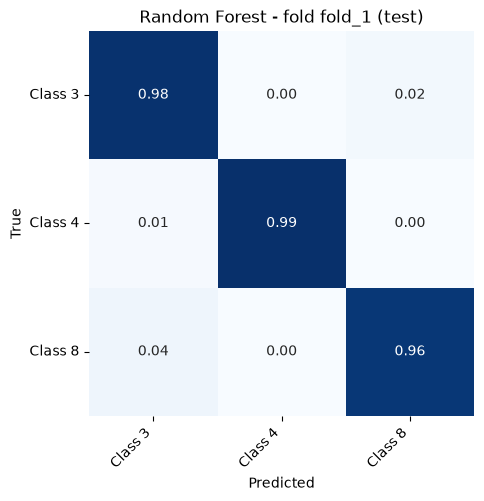

In [3]:
# ============================================================
# TOOLKIT FIRST: ONE RANDOM FOREST ON FOLD 1
# ============================================================
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

from ThreeWToolkit.assessment import AssessmentVisualizationConfig
from ThreeWToolkit.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from ThreeWToolkit.models import SklearnModelsConfig
from src.supervised_classification import prepare_window_data

first_fold = sorted(set(test_fold_info))[0]
pick = lambda values, info: [v for v, f in zip(values, info) if f == first_fold]

# Flatten the windows and balance the training set (our helper)
X_train, y_train, X_test, y_test, label_encoder = prepare_window_data(
    train_dfs=pick(train_dfs, train_fold_info),
    train_classes=pick(train_classes, train_fold_info),
    test_dfs=pick(test_dfs, test_fold_info),
    test_classes=pick(test_classes, test_fold_info),
    selected_classes=selected_classes,
)

# 1. Model from a toolkit configuration
toolkit_model = SklearnModelsConfig(
    model_type=RandomForestClassifier,
    model_params={"n_estimators": 100, "max_depth": 15, "random_state": 42, "n_jobs": -1},
).build()
print(f"Model: {toolkit_model.model_name} | training windows: {X_train.shape}")

# 2. Fit and predict
toolkit_model.model.fit(X_train, y_train)
y_pred = toolkit_model.model.predict(X_test)

# 3. Toolkit metrics
print(f"\nFold {first_fold} - test windows: {len(y_test)}")
print(f"   Accuracy          : {accuracy_score(y_test, y_pred):.3f}")
print(f"   Balanced accuracy : {balanced_accuracy_score(y_test, y_pred):.3f}")
for name, metric in (("Precision", precision_score), ("Recall", recall_score), ("F1", f1_score)):
    print(f"   {name + ' (macro)':<18}: {metric(y_test, y_pred, average='macro', zero_division=0):.3f}")

# 4. Toolkit confusion matrix (row-normalized)
plotter = AssessmentVisualizationConfig(
    class_names=[f"Class {c}" for c in label_encoder.classes_]
).build()
plotter.plot_confusion_matrix(
    y_true=y_test,
    y_pred=y_pred,
    title=f"Random Forest - fold {first_fold} (test)",
    figsize=(6, 5),
)
plt.show()

### The by-fold analysis: one loop, seven models

The next cell repeats this flow for every fold and every algorithm. The seven models are listed in `MODELS` (a class and its parameters), and each estimator is created with the same `SklearnModelsConfig(...).build()`; the metrics are the toolkit ones. What we add is **our own** loop: the balanced training set of each fold, the SVMs trained on a random subset of 1000 windows (they are slow on 900 features), and the per-fold tables and the overfitting and consistency comparisons that follow. The loop trains every model once per fold; the tables below only slice its results by algorithm family.

In [4]:

# ============================================================
# TRAIN THE SEVEN MODELS ON EVERY FOLD
# ============================================================
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from ThreeWToolkit.metrics import accuracy_score, balanced_accuracy_score
from ThreeWToolkit.models import SklearnModelsConfig
from src.supervised_classification import prepare_window_data

MLP_COMMON = dict(activation="relu", solver="adam", random_state=42, early_stopping=True)
MODELS = {
    "Decision Tree": (
        DecisionTreeClassifier,
        dict(max_depth=10, min_samples_split=20, min_samples_leaf=10, random_state=42),
    ),
    "Random Forest": (
        RandomForestClassifier,
        dict(n_estimators=100, max_depth=15, min_samples_split=10, min_samples_leaf=5, random_state=42, n_jobs=-1),
    ),
    "Linear SVM": (SVC, dict(kernel="linear", C=1.0, random_state=42)),
    "RBF SVM": (SVC, dict(kernel="rbf", C=1.0, gamma="scale", random_state=42)),
    "Simple Neural Network": (
        MLPClassifier,
        dict(hidden_layer_sizes=(100,), alpha=0.0001, max_iter=200, validation_fraction=0.1, n_iter_no_change=10, **MLP_COMMON),
    ),
    "Deep Neural Network": (
        MLPClassifier,
        dict(hidden_layer_sizes=(200, 100, 50), alpha=0.0001, max_iter=200, validation_fraction=0.1, n_iter_no_change=10, **MLP_COMMON),
    ),
    "Regularized Neural Network": (
        MLPClassifier,
        dict(hidden_layer_sizes=(150, 100), alpha=0.001, learning_rate="adaptive", max_iter=300, validation_fraction=0.15, n_iter_no_change=15, **MLP_COMMON),
    ),
}
SVM_SAMPLES = 1000  # the SVMs are trained on a random subset of the training windows

if selected_classes is None:  # every fault type, without normal operation
    wanted = lambda cls: str(cls) != "0"
else:
    wanted = lambda cls: str(cls) in {str(c) for c in selected_classes}


def windows_of(fold, dfs, classes, info):
    pairs = [(d, c) for d, c, f in zip(dfs, classes, info) if f == fold and wanted(c)]
    return [d for d, _ in pairs], [c for _, c in pairs]


rows, fold_results = [], {}
for fold in sorted(set(train_fold_info)):
    fold_train_dfs, fold_train_classes = windows_of(fold, train_dfs, train_classes, train_fold_info)
    fold_test_dfs, fold_test_classes = windows_of(fold, test_dfs, test_classes, test_fold_info)
    X_train, y_train, X_test, y_test, label_encoder = prepare_window_data(
        fold_train_dfs, fold_train_classes, fold_test_dfs, fold_test_classes,
        selected_classes=selected_classes,
    )
    print(f"{fold}: {len(X_train)} training windows (balanced), {len(X_test)} test windows")

    svm_subset = None
    fold_results[fold] = {}
    for name, (model_type, params) in MODELS.items():
        X_fit, y_fit, X_eval, y_eval = X_train, y_train, X_test, y_test
        if name.endswith("SVM"):
            if svm_subset is None:  # drawn once per fold, shared by the two SVMs
                svm_subset = (
                    np.random.choice(len(X_train), min(SVM_SAMPLES, len(X_train)), replace=False),
                    np.random.choice(len(X_test), min(SVM_SAMPLES // 2, len(X_test)), replace=False),
                )
            X_fit, y_fit = X_train[svm_subset[0]], y_train[svm_subset[0]]
            X_eval, y_eval = X_test[svm_subset[1]], y_test[svm_subset[1]]

        start = time.time()
        model = SklearnModelsConfig(model_type=model_type, model_params=params).build().model
        model.fit(X_fit, y_fit)
        elapsed = time.time() - start

        y_eval_pred = model.predict(X_eval)
        rows.append(
            {
                "Fold": fold,
                "Model": name,
                "Train Acc": accuracy_score(y_fit, model.predict(X_fit)),
                "Test Acc": accuracy_score(y_eval, y_eval_pred),
                "Test Bal. Acc": balanced_accuracy_score(y_eval, y_eval_pred),
                "Time (s)": elapsed,
                "Train windows": len(X_fit),
            }
        )
        fold_results[fold][name] = rows[-1]["Test Acc"]

fold_table = pd.DataFrame(rows)
fold_table["Overfitting"] = fold_table["Train Acc"] - fold_table["Test Acc"]

# Results of the last fold (train accuracy, time), used by the comparison below
results = [
    {
        "model_name": row.Model,
        "train_accuracy": row["Train Acc"],
        "test_accuracy": row["Test Acc"],
        "training_time": row["Time (s)"],
    }
    for _, row in fold_table[fold_table.Fold == fold_table.Fold.iloc[-1]].iterrows()
]
print("\n✅ Training completed:", len(fold_table), "models trained")


def show_family(model_names):
    '''Per-fold table and cross-fold summary of some of the models.'''
    table = fold_table[fold_table.Model.isin(model_names)]
    print(table.drop(columns="Train windows").round(3).to_string(index=False))
    summary = table.groupby("Model")["Test Acc"].agg(Avg="mean", Range=lambda s: s.max() - s.min())
    print("\n📈 STATISTICAL COMPARISON (test accuracy across folds)")
    print(summary.round(3).to_string())


fold_1: 3000 training windows (balanced), 673 test windows


fold_2: 3000 training windows (balanced), 704 test windows


fold_3: 3000 training windows (balanced), 689 test windows



✅ Training completed: 21 models trained


## Tree-Based Algorithms Theory

**Decision Trees:**
- **How they work** - Split data based on feature values to separate classes
- **Interpretability** - Easy to understand and visualize decision paths
- **Strengths** - Handle non-linear patterns, robust to outliers
- **Weaknesses** - Prone to overfitting, unstable (small data changes = different tree)

**Random Forest:**
- **Ensemble method** - Combines many decision trees for better performance
- **Bootstrap aggregating** - Each tree trained on random data subset
- **Feature randomness** - Each split considers random subset of features
- **Benefits** - Reduces overfitting, more stable, provides feature importance

**For oil well data:** Good at capturing threshold-based rules (e.g., "if pressure > X and temperature < Y, then fault type Z")

In [5]:
# ============================================================
# DECISION TREES - BY FOLD
# ============================================================
print("🌳 TREE-BASED MODELS - BY FOLD")
print("=" * 50)
show_family(["Decision Tree", "Random Forest"])

🌳 TREE-BASED MODELS - BY FOLD
  Fold         Model  Train Acc  Test Acc  Test Bal. Acc  Time (s)  Overfitting
fold_1 Decision Tree      0.989     0.964          0.963     0.697        0.025
fold_1 Random Forest      0.994     0.970          0.974     0.417        0.023
fold_2 Decision Tree      0.990     0.952          0.955     0.587        0.038
fold_2 Random Forest      0.993     0.982          0.983     0.376        0.011
fold_3 Decision Tree      0.995     0.916          0.906     0.483        0.079
fold_3 Random Forest      0.996     0.938          0.940     0.314        0.058

📈 STATISTICAL COMPARISON (test accuracy across folds)
                 Avg  Range
Model                      
Decision Tree  0.944  0.049
Random Forest  0.963  0.044


# ⚡ Support Vector Machines (SVM)

**How SVM Works**: Finds the best boundary (hyperplane) to separate different classes with maximum margin.

**Key Advantages**:
- Effective with high-dimensional data (many features)
- Memory efficient (uses only support vectors)
- Different kernels for different data patterns

**For Oil Well Data**: Handles flattened time series well, RBF kernel captures non-linear sensor patterns.

In [6]:
# ============================================================
# SVM - BY FOLD
# ============================================================
print("⚡ SVM MODELS - BY FOLD")
print("=" * 45)
print(f"Trained on a random subset of {SVM_SAMPLES} windows per fold\n")
show_family(["Linear SVM", "RBF SVM"])

⚡ SVM MODELS - BY FOLD
Trained on a random subset of 1000 windows per fold

  Fold      Model  Train Acc  Test Acc  Test Bal. Acc  Time (s)  Overfitting
fold_1 Linear SVM      0.900     0.974          0.979     0.256       -0.074
fold_1    RBF SVM      0.841     0.972          0.977     0.218       -0.131
fold_2 Linear SVM      0.905     0.976          0.979     0.239       -0.071
fold_2    RBF SVM      0.833     0.986          0.990     0.190       -0.153
fold_3 Linear SVM      0.908     0.808          0.845     0.301        0.100
fold_3    RBF SVM      0.889     0.946          0.952     0.152       -0.057

📈 STATISTICAL COMPARISON (test accuracy across folds)
              Avg  Range
Model                   
Linear SVM  0.919  0.168
RBF SVM     0.968  0.040


# 🧠 Neural Networks

**How Neural Networks Work**: Interconnected layers of neurons that learn complex patterns through training.

**Key Components**:
- **Neurons**: Process input and apply activation functions
- **Layers**: Input → Hidden → Output
- **Backpropagation**: Adjusts weights based on errors

**Types Used**:
- **Simple NN**: Fast baseline, good for simple patterns
- **Deep NN**: Multiple hidden layers for complex patterns
- **Regularized NN**: Uses dropout to prevent overfitting

**For Time Series**: Can automatically discover patterns in sensor data and handle complex temporal relationships.

In [7]:
# ============================================================
# NEURAL NETWORKS - BY FOLD
# ============================================================
print("🧠 NEURAL NETWORK MODELS - BY FOLD")
print("=" * 55)
show_family(["Simple Neural Network", "Deep Neural Network", "Regularized Neural Network"])

print("\nArchitectures:")
for name in ("Simple Neural Network", "Deep Neural Network", "Regularized Neural Network"):
    params = MODELS[name][1]
    print(f"   {name}: hidden layers {params['hidden_layer_sizes']}, alpha {params['alpha']}")

🧠 NEURAL NETWORK MODELS - BY FOLD
  Fold                      Model  Train Acc  Test Acc  Test Bal. Acc  Time (s)  Overfitting
fold_1      Simple Neural Network      0.936     0.970          0.976     2.372       -0.034
fold_1        Deep Neural Network      0.977     0.973          0.978    12.345        0.004
fold_1 Regularized Neural Network      0.992     0.972          0.977    11.118        0.020
fold_2      Simple Neural Network      0.932     0.997          0.997     2.792       -0.065
fold_2        Deep Neural Network      0.985     0.984          0.985     9.620        0.001
fold_2 Regularized Neural Network      0.989     0.996          0.996    10.714       -0.006
fold_3      Simple Neural Network      0.979     0.959          0.958     2.115        0.019
fold_3        Deep Neural Network      0.994     0.954          0.957     5.542        0.041
fold_3 Regularized Neural Network      0.992     0.956          0.958     3.781        0.036

📈 STATISTICAL COMPARISON (test accu

## Comprehensive Results Analysis

**Visualization goals:**
- **Algorithm comparison** - Which performs best for oil well fault detection?
- **Overfitting assessment** - Are models generalizing well to new data?
- **Performance patterns** - What insights can guide future improvements?

**Key analyses:**
1. **Test accuracy ranking** - Real-world performance comparison
2. **Train vs test gap** - Generalization assessment
- **High train, low test** - Overfitting (model too complex)
- **Similar train/test** - Good generalization
- **Low both** - Underfitting (model too simple or insufficient data)
3. **Algorithm categories** - Tree-based vs SVM vs Neural Network strengths
4. **Statistical significance** - Are performance differences meaningful?

**Decision-making criteria:**
- **Primary metric** - Test accuracy (real-world performance)
- **Secondary factors** - Training time, interpretability, stability
- **Domain constraints** - Real-time requirements, maintenance complexity

## Understanding the training loop

**What just happened?** One loop ran a complete experiment, fold by fold:

### 1. Class balancing (training set only)
- `prepare_window_data` keeps the selected classes, balances the training windows with the "combined" strategy (undersample the majority classes, oversample the minority ones) and caps each class at 1000 windows
- The test windows are **not** balanced: they keep the real class distribution (only capped, to a third of that)

### 2. One fold at a time
- Each fold trains on its own training windows and is tested on its own real test windows
- Balancing is applied to each fold separately, so no test information reaches the training

### 3. Seven algorithms per fold
- Decision Tree and Random Forest (tree-based)
- Linear SVM and RBF SVM (trained on a random subset of 1000 windows)
- Simple, Deep and Regularized neural networks (`MLPClassifier`)

### 4. Evaluation
- Accuracy and balanced accuracy on the test windows, train accuracy, training time and overfitting (train - test), all with the toolkit metrics
- The cross-fold tables and charts below use the test accuracy of each fold

**Key insight:** `SklearnModelsConfig` creates every estimator the same way, so the whole comparison is a dictionary and a loop.

> 📖 **In the book — Appendix E, §*Caderno 4* ("Balancing the training set and not the test set").** The asymmetry above is deliberate and is often inverted by mistake. Balancing the **training** set helps the model learn the rare classes; balancing the **test** set *changes the question* — it measures performance under a distribution that does not exist in operation. For imbalance in the evaluation, the right tool is balanced accuracy (Chapter 4), not resampling the test set.
>
> Note also that class **4** (flow instability) is among the selected classes: it is the symptomatic class that appears at the bottom of every table in the book. Seeing it happen with a random forest, in a few minutes, is the cheapest way to understand the taxonomy argument of Chapter 16.

In [8]:
# ============================================================
# RESULTS SUMMARY
# ============================================================

# Best model of the last fold
best_model = max(results, key=lambda x: x["test_accuracy"])

# ============================================================
# CROSS-FOLD VALIDATION RESULTS
# ============================================================

if fold_results:
    print("📈 CROSS-FOLD VALIDATION")
    print("=" * 35)

    fold_names = sorted(fold_results.keys())

    if fold_names and results:
        model_names = [r["model_name"] for r in results]

        # Table header
        header = f"{'Fold':<12}"
        for model_name in model_names:
            short_name = model_name.replace(" Neural Network", " NN").replace(
                "Random Forest", "RF"
            )[:10]
            header += f"{short_name:<12}"
        print(f"\n{header}")
        print("-" * len(header))

        # Fold results
        for fold in fold_names:
            row = f"{fold:<12}"
            for model_name in model_names:
                accuracy = fold_results[fold].get(model_name, 0.0)
                row += f"{accuracy:<12.3f}"
            print(row)

        # Calculate averages
        print("-" * len(header))
        avg_row = f"{'Average':<12}"
        for model_name in model_names:
            accuracies = [
                fold_results[fold].get(model_name, 0.0) for fold in fold_names
            ]
            avg_accuracy = np.mean(accuracies) if accuracies else 0.0
            avg_row += f"{avg_accuracy:<12.3f}"
        print(avg_row)

        # Store for later analysis
        fold_accuracies = fold_results

else:
    print("❌ Cross-fold validation not available")

📈 CROSS-FOLD VALIDATION

Fold        Decision T  RF          Linear SVM  RBF SVM     Simple NN   Deep NN     Regularize  
------------------------------------------------------------------------------------------------
fold_1      0.964       0.970       0.974       0.972       0.970       0.973       0.972       
fold_2      0.952       0.982       0.976       0.986       0.997       0.984       0.996       
fold_3      0.916       0.938       0.808       0.946       0.959       0.954       0.956       
------------------------------------------------------------------------------------------------
Average     0.944       0.963       0.919       0.968       0.976       0.970       0.975       


🎯 GENERATING COMPREHENSIVE VISUALIZATIONS - CROSS-FOLD AVERAGES
📊 Using averaged results across 3 folds
   • Fold variance indicates consistency across different data splits


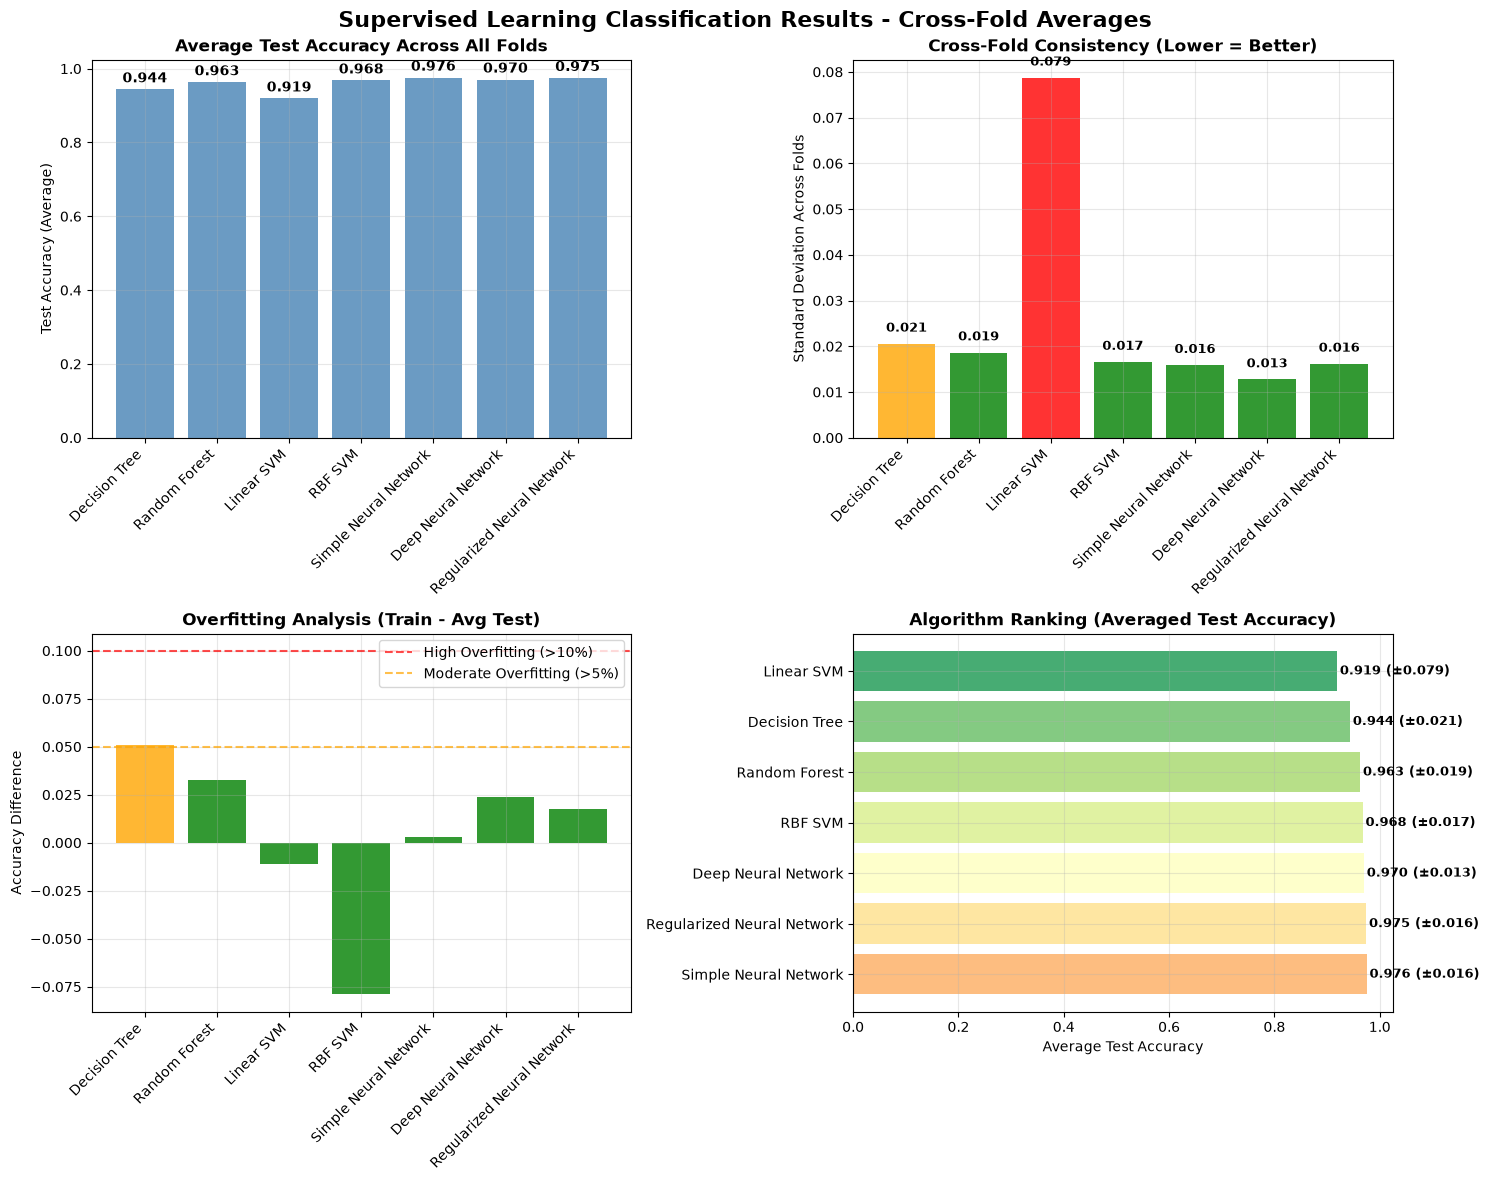


📋 DETAILED RESULTS TABLE - CROSS-FOLD AVERAGES
                 Algorithm Avg Test Accuracy Fold Std Dev Consistency Overfitting Generalization
     Simple Neural Network             0.976        0.016      ✅ High       0.003         ✅ Good
Regularized Neural Network             0.975        0.016      ✅ High       0.017         ✅ Good
       Deep Neural Network             0.970        0.013      ✅ High       0.024         ✅ Good
                   RBF SVM             0.968        0.017      ✅ High      -0.079         ✅ Good
             Random Forest             0.963        0.019      ✅ High       0.033         ✅ Good
             Decision Tree             0.944        0.021    🔶 Medium       0.051     🔶 Moderate
                Linear SVM             0.919        0.079      ⚠️ Low      -0.011         ✅ Good

📊 CROSS-FOLD SUMMARY STATISTICS
🎯 Best Algorithm: Simple Neural Network (0.976 ± 0.016)
📈 Average Test Accuracy: 0.959
📉 Worst Algorithm: Linear SVM (0.919 ± 0.079)
🔄 Accuracy

In [9]:
# ============================================================
# 📈 RESULTS VISUALIZATION AND ANALYSIS - CROSS-FOLD AVERAGES
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set plotting style
plt.style.use("default")
sns.set_palette("husl")

if "fold_accuracies" in locals() and fold_accuracies:
    print("🎯 GENERATING COMPREHENSIVE VISUALIZATIONS - CROSS-FOLD AVERAGES")
    print("=" * 65)

    # ============================================================
    # EXTRACT AVERAGED FOLD RESULTS
    # ============================================================

    # Get model names from original results for consistency
    original_results = results
    model_names = [r["model_name"] for r in original_results]

    # Calculate averaged results across all folds
    fold_names = sorted(fold_accuracies.keys())
    averaged_results = []

    for model_name in model_names:
        # Get accuracies across all folds for this model
        fold_accs = [fold_accuracies[fold].get(model_name, 0.0) for fold in fold_names]
        avg_test_acc = np.mean(fold_accs) if fold_accs else 0.0

        # Find corresponding original result for train accuracy and time
        original_result = next(
            (r for r in original_results if r["model_name"] == model_name), None
        )
        train_acc = original_result["train_accuracy"] if original_result else 0.0
        train_time = original_result["training_time"] if original_result else 0.0

        averaged_results.append(
            {
                "model_name": model_name,
                "test_accuracy": avg_test_acc,
                "train_accuracy": train_acc,  # Note: this is from single fold
                "training_time": train_time,
                "fold_variance": np.std(fold_accs) if len(fold_accs) > 1 else 0.0,
            }
        )

    # Extract data for plotting - NOW USING CROSS-FOLD AVERAGES
    test_accuracies = [r["test_accuracy"] for r in averaged_results]
    train_accuracies = [r["train_accuracy"] for r in averaged_results]
    fold_variances = [r["fold_variance"] for r in averaged_results]

    print(f"📊 Using averaged results across {len(fold_names)} folds")
    print("   • Fold variance indicates consistency across different data splits")

    # ============================================================
    # 1. PERFORMANCE COMPARISON BAR CHART
    # ============================================================

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(
        "Supervised Learning Classification Results - Cross-Fold Averages",
        fontsize=16,
        fontweight="bold",
    )

    # Bar chart of test accuracies (AVERAGED ACROSS FOLDS)
    bars1 = ax1.bar(
        range(len(model_names)), test_accuracies, alpha=0.8, color="steelblue"
    )
    ax1.set_title("Average Test Accuracy Across All Folds", fontweight="bold")
    ax1.set_ylabel("Test Accuracy (Average)")
    ax1.set_xticks(range(len(model_names)))
    ax1.set_xticklabels(model_names, rotation=45, ha="right")
    ax1.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, acc) in enumerate(zip(bars1, test_accuracies)):
        ax1.text(
            bar.get_x() + bar.get_width() / 2.0,
            bar.get_height() + 0.01,
            f"{acc:.3f}",
            ha="center",
            va="bottom",
            fontweight="bold",
        )

    # ============================================================
    # 2. FOLD CONSISTENCY ANALYSIS (VARIANCE)
    # ============================================================

    # Color by variance (low variance = green, high variance = red)
    colors_variance = [
        "green" if v < 0.02 else "orange" if v < 0.05 else "red" for v in fold_variances
    ]

    bars2 = ax2.bar(
        range(len(model_names)), fold_variances, alpha=0.8, color=colors_variance
    )
    ax2.set_title("Cross-Fold Consistency (Lower = Better)", fontweight="bold")
    ax2.set_ylabel("Standard Deviation Across Folds")
    ax2.set_xticks(range(len(model_names)))
    ax2.set_xticklabels(model_names, rotation=45, ha="right")
    ax2.grid(True, alpha=0.3)

    # Add value labels
    for i, (bar, var) in enumerate(zip(bars2, fold_variances)):
        ax2.text(
            bar.get_x() + bar.get_width() / 2.0,
            bar.get_height() + 0.002,
            f"{var:.3f}",
            ha="center",
            va="bottom",
            fontweight="bold",
            fontsize=9,
        )

    # ============================================================
    # 3. OVERFITTING ANALYSIS (Note: Train is from single fold)
    # ============================================================

    # Calculate overfitting (train - averaged test accuracy)
    overfitting = [
        train - test for train, test in zip(train_accuracies, test_accuracies)
    ]
    colors = [
        "red" if x > 0.1 else "orange" if x > 0.05 else "green" for x in overfitting
    ]

    bars4 = ax3.bar(range(len(model_names)), overfitting, alpha=0.8, color=colors)
    ax3.set_title("Overfitting Analysis (Train - Avg Test)", fontweight="bold")
    ax3.set_ylabel("Accuracy Difference")
    ax3.set_xticks(range(len(model_names)))
    ax3.set_xticklabels(model_names, rotation=45, ha="right")
    ax3.axhline(
        y=0.1, color="red", linestyle="--", alpha=0.7, label="High Overfitting (>10%)"
    )
    ax3.axhline(
        y=0.05,
        color="orange",
        linestyle="--",
        alpha=0.7,
        label="Moderate Overfitting (>5%)",
    )
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # ============================================================
    # 4. ALGORITHM RANKING BY AVERAGED PERFORMANCE
    # ============================================================

    # Sort by averaged test accuracy
    sorted_results = sorted(
        zip(model_names, test_accuracies, fold_variances),
        key=lambda x: x[1],
        reverse=True,
    )
    sorted_names, sorted_accs, sorted_vars = zip(*sorted_results)

    colors_ranking = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(sorted_names)))
    bars5 = ax4.barh(
        range(len(sorted_names)), sorted_accs, alpha=0.8, color=colors_ranking
    )
    ax4.set_title("Algorithm Ranking (Averaged Test Accuracy)", fontweight="bold")
    ax4.set_xlabel("Average Test Accuracy")
    ax4.set_yticks(range(len(sorted_names)))
    ax4.set_yticklabels(sorted_names)
    ax4.grid(True, alpha=0.3)

    # Add value labels with variance info
    for i, (bar, acc, var) in enumerate(zip(bars5, sorted_accs, sorted_vars)):
        ax4.text(
            bar.get_width() + 0.005,
            bar.get_y() + bar.get_height() / 2.0,
            f"{acc:.3f} (±{var:.3f})",
            ha="left",
            va="center",
            fontweight="bold",
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

    # ============================================================
    # 5. DETAILED RESULTS TABLE - CROSS-FOLD AVERAGES
    # ============================================================

    print("\n📋 DETAILED RESULTS TABLE - CROSS-FOLD AVERAGES")
    print("=" * 70)

    # Create DataFrame for better visualization
    df_results = pd.DataFrame(
        {
            "Algorithm": model_names,
            "Avg Test Accuracy": [f"{acc:.3f}" for acc in test_accuracies],
            "Fold Std Dev": [f"{var:.3f}" for var in fold_variances],
            "Consistency": [
                "✅ High" if var < 0.02 else "🔶 Medium" if var < 0.05 else "⚠️ Low"
                for var in fold_variances
            ],
            "Overfitting": [f"{diff:.3f}" for diff in overfitting],
            "Generalization": [
                "⚠️ High" if diff > 0.1 else "🔶 Moderate" if diff > 0.05 else "✅ Good"
                for diff in overfitting
            ],
        }
    )

    # Sort by averaged test accuracy
    df_results = df_results.sort_values("Avg Test Accuracy", ascending=False)
    print(df_results.to_string(index=False))

    # ============================================================
    # 6. SUMMARY STATISTICS - CROSS-FOLD AVERAGES
    # ============================================================

    print("\n📊 CROSS-FOLD SUMMARY STATISTICS")
    print("=" * 40)
    print(
        f"🎯 Best Algorithm: {sorted_names[0]} ({sorted_accs[0]:.3f} ± {sorted_vars[0]:.3f})"
    )
    print(f"📈 Average Test Accuracy: {np.mean(test_accuracies):.3f}")
    print(
        f"📉 Worst Algorithm: {sorted_names[-1]} ({sorted_accs[-1]:.3f} ± {sorted_vars[-1]:.3f})"
    )
    print(f"🔄 Accuracy Range: {max(test_accuracies) - min(test_accuracies):.3f}")

    # Count consistency levels
    high_consistency = sum(1 for x in fold_variances if x < 0.02)
    medium_consistency = sum(1 for x in fold_variances if 0.02 <= x < 0.05)
    low_consistency = sum(1 for x in fold_variances if x >= 0.05)

    print("\n🔄 CROSS-FOLD CONSISTENCY ANALYSIS:")
    print(
        f"   ✅ High Consistency: {high_consistency}/{len(averaged_results)} algorithms"
    )
    print(
        f"   🔶 Medium Consistency: {medium_consistency}/{len(averaged_results)} algorithms"
    )
    print(f"   ⚠️ Low Consistency: {low_consistency}/{len(averaged_results)} algorithms")

    # Most consistent algorithm
    most_consistent = min(zip(model_names, fold_variances), key=lambda x: x[1])
    print(
        f"\n🏆 Most Consistent Algorithm: {most_consistent[0]} (std: {most_consistent[1]:.3f})"
    )

    print("\n🎓 CROSS-FOLD LEARNING INSIGHTS:")
    print(f"   • Results averaged across {len(fold_names)} cross-validation folds")
    print("   • Consistency measured by standard deviation across folds")
    print("   • Best algorithm combines high accuracy with low variance")
    print(f"   • Classes analyzed: {selected_classes}")

    print("\n✅ Cross-fold visualization complete! Robust performance estimates ready.")

else:
    print("❌ No cross-fold results available.")
    print("💡 Please run all the previous cells first:")
    print("   1. Data loading and configuration")
    print("   2. Model training and validation")
    print("   3. Cross-fold validation analysis")
    print("\nThen re-run this cell to see cross-fold averaged visualizations.")

## ⚠️ Does the sensor level identify the well?

The toolkit `Normalize` keeps the **absolute level** of every sensor, and that level depends on the well (depth, completion, instrumentation). Folds built **by event** put events of the same well on both sides of the split, so a model can score well by recognizing the well instead of the fault. The cell below checks this on a small sample of real events, taken in turn from each well:

1. can a random forest tell **which well** a window comes from, under each scaling?
2. how does the **fault-class** balanced accuracy change when the folds are built by well, so that the test well is never seen in training?

It is a small experiment (a few dozen events, one model, one seed), meant to expose the effect and not to rank scalers.

In [10]:
# ============================================================
# DOES THE SENSOR LEVEL IDENTIFY THE WELL?
# ============================================================
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from ThreeWToolkit.dataset import ParquetDataset, ParquetDatasetConfig

warnings.filterwarnings("ignore")
CLASSES, PER_CLASS = [0] + list(config.SELECTED_ANOMALY_CLASSES), 50
WIN = config.WINDOW_SIZE
STEP = int(WIN * (1 - config.WINDOW_OVERLAP))
SENSORS = [c for c in config.TARGET_FEATURES if c != config.CLASS_COLUMN]

# Real events, taken in turn from each well so that every class spreads over wells
files = ParquetDataset(
    ParquetDatasetConfig(
        path="../../dataset/", event_type=["real"], target_class=CLASSES,
        columns=SENSORS, target_column=None,
    )
).files_events
by_class_well = {}
for f in sorted(files):
    well = re.search(r"WELL-(\d+)", f.name).group(1)
    by_class_well.setdefault(int(f.parent.name), {}).setdefault(well, []).append(f)
events, labels, wells = [], [], []
for c, per_well in by_class_well.items():
    chosen = []
    while len(chosen) < PER_CLASS and any(per_well.values()):
        for w, fs in sorted(per_well.items()):
            if fs and len(chosen) < PER_CLASS:
                chosen.append((w, fs.pop(0)))
    for w, f in chosen:
        x = pd.read_parquet(Path("../../dataset") / f, columns=SENSORS).iloc[:: config.SAMPLING_RATE].ffill().bfill()
        if len(x) >= WIN and not x.isna().any().any():
            events.append(x.to_numpy(float)); labels.append(c); wells.append(w)
labels, wells = np.array(labels), np.array(wells)
print(f"{len(events)} real events from {len(set(wells))} wells")
for c in CLASSES:
    print(f"   class {c}: {(labels == c).sum()} events, {len(set(wells[labels == c]))} wells")


def scale(kind, train):
    """Scale every event; statistics of the global kinds come from the training events only."""
    cat = np.concatenate([events[i] for i in train])
    mu, sd = cat.mean(0), cat.std(0) + 1e-8
    out = []
    for x in events:
        if kind == "minmax per event":
            out.append((x - x.min(0)) / (x.max(0) - x.min(0) + 1e-8))
        elif kind == "global z-score (Normalize)":
            out.append((x - mu) / sd)
        else:  # global scale, level of each event removed
            out.append((x - np.median(x, 0)) / sd)
    return out


def windows(idx, scaled):
    X, e = [], []
    for i in idx:
        w = np.stack([scaled[i][s : s + WIN] for s in range(0, len(scaled[i]) - WIN + 1, STEP)])
        X.append(w.reshape(len(w), -1)); e += [i] * len(w)
    return np.concatenate(X), np.array(e)


KINDS = ["minmax per event", "global z-score (Normalize)", "global scale, event level removed"]
ids = np.arange(len(events))

# 1) Can a forest tell which well a window comes from? (events of a well are in train and test)
print("\n1) Window -> well (chance = %.2f)" % (1 / len(set(wells))))
for kind in KINDS:
    hits = []
    for tr, te in StratifiedKFold(3, shuffle=True, random_state=0).split(ids, labels):
        sc = scale(kind, tr)
        Xtr, etr = windows(tr, sc); Xte, ete = windows(te, sc)
        known = np.isin(wells[ete], wells[etr])
        m = RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1).fit(Xtr, wells[etr])
        hits.append((m.predict(Xte) == wells[ete])[known].mean())
    print(f"   {kind:36s} well hit rate = {np.mean(hits):.2f}")

# 2) Fault class: folds by event (same well may be on both sides) x folds by well (unseen well)
print("\n2) Fault class, balanced accuracy")
splits = {
    "folds by event": list(StratifiedKFold(3, shuffle=True, random_state=42).split(ids, labels)),
    "folds by WELL ": list(GroupKFold(3).split(ids, labels, groups=wells)),
}
print(f"   {'':36s}" + "".join(f"{n:>18s}" for n in splits))
for kind in KINDS:
    cells = []
    for name, sp in splits.items():
        accs = []
        for tr, te in sp:
            sc = scale(kind, tr)
            Xtr, etr = windows(tr, sc); Xte, ete = windows(te, sc)
            m = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1).fit(Xtr, labels[etr])
            accs.append(balanced_accuracy_score(labels[ete], m.predict(Xte)))
        cells.append(f"{np.mean(accs):.2f} ± {np.std(accs):.2f}")
    print(f"   {kind:36s}" + "".join(f"{c:>18s}" for c in cells))


2026-11-04 16:36:12,391 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-04 16:36:12,392 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-04 16:36:12,393 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


113 real events from 12 wells
   class 0: 37 events, 7 wells
   class 3: 32 events, 2 wells
   class 4: 36 events, 5 wells
   class 8: 8 events, 5 wells

1) Window -> well (chance = 0.08)


   minmax per event                     well hit rate = 0.57


   global z-score (Normalize)           well hit rate = 0.96


   global scale, event level removed    well hit rate = 0.67

2) Fault class, balanced accuracy
                                           folds by event    folds by WELL 


   minmax per event                           0.57 ± 0.11       0.23 ± 0.15


   global z-score (Normalize)                 0.90 ± 0.05       0.30 ± 0.21


   global scale, event level removed          0.69 ± 0.07       0.47 ± 0.11


**How to read it.**

- With the toolkit `Normalize`, a window gives away its well almost always (about 0.96, chance is 0.08). With the per-event Min-Max the level is erased and the rate drops to about 0.57; the rest is the *shape* of the series.
- Folds by event with `Normalize` reach about 0.90, but with unseen wells the same model falls to about 0.30, close to the per-event Min-Max. Most of the gain was **recognizing the well**, not the fault.
- Removing only the level of each event, while keeping the global scale, is the best option on unseen wells (about 0.47). The toolkit `Normalize` cannot do this by itself.
- The wells-by-class table limits what any scaler can do: class 3 comes from only 2 wells and class 8 has 8 events. Unseen-well numbers vary a lot (see the standard deviations), so read them as an indication.

This is why the near-perfect scores of this and of the previous notebooks should not be read as generalization to a new well. It is the same concern of Chapter 4 (*validation*): the split must respect the unit that the model will meet in operation.

## 📖 Guided exercises (book, Appendix E — exercises 3 and 5)

1. Implement the provenance policy of the book (`NON_REAL_EVENT_TYPES` in `src/config.py`, then re-run notebooks 1 and 4) and compare the results of this notebook under the two policies.
2. Run this notebook with `selected_classes = None` and compare the performance of classes 4 and 5 with that of the others. Does the pattern described in Chapter 16 of the book reproduce?

> 📖 *Lopes et al. (2026), Appendix E — "Roteiro prático com o repositório 3W"* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)).